
### importing the nessecary libs:

In [44]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
from data_profiling import ProfileReport
from pathlib import Path

from sklearn.preprocessing import OrdinalEncoder

### getting the data from kaggle

In [3]:
ROOT = Path().cwd().parent
dataset = ROOT / "data" / "raw" / "student-mental.csv"
ARTIFACT_PATH = ROOT / "artifacts"

In [4]:
print("Path to dataset files:", dataset,",exist :",dataset.exists())
df = pd.read_csv(dataset)

Path to dataset files: c:\Users\Youcode\Documents\DEV_AI\sprint_1\soutnance_1\data\raw\student-mental.csv ,exist : True


### comprendre la structure générale du jeu de données (types de données, dimensions, aperçus)



In [5]:
df.shape


(2000, 17)

In [6]:
df.dtypes

Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object

In [7]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

### Statistiques descriptives


In [9]:
print("Duplicate rows:", df.duplicated().sum())                   # 0
print("Rows with missing values:", df.isna().any(axis=1).sum())  # 394

Duplicate rows: 0
Rows with missing values: 394


In [10]:
df.describe(include=np.number)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [11]:
df.describe(include=np.object_)

,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


In [12]:
categories = df.select_dtypes(include="object")
for categorie in categories:
    if categorie != "Student_ID":
        display(df[categorie].value_counts(normalize=True))

Gender
Female        0.4855
Male          0.4660
Non-binary    0.0485
Name: proportion, dtype: float64

Physical_Activity
Moderate    0.4530
Low         0.3395
High        0.2075
Name: proportion, dtype: float64

Part_Time_Job
No     0.6445
Yes    0.3555
Name: proportion, dtype: float64

Diet_Quality
Average    0.445365
Poor       0.303988
Good       0.250647
Name: proportion, dtype: float64

Previous_Mental_Health_History
No     0.704
Yes    0.296
Name: proportion, dtype: float64

Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64

In [13]:
def save_plot(filename):
    plt.savefig(ARTIFACT_PATH / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

### Visualisation des valeurs manquantes et duplications


[<BarContainer object of 7 artists>]


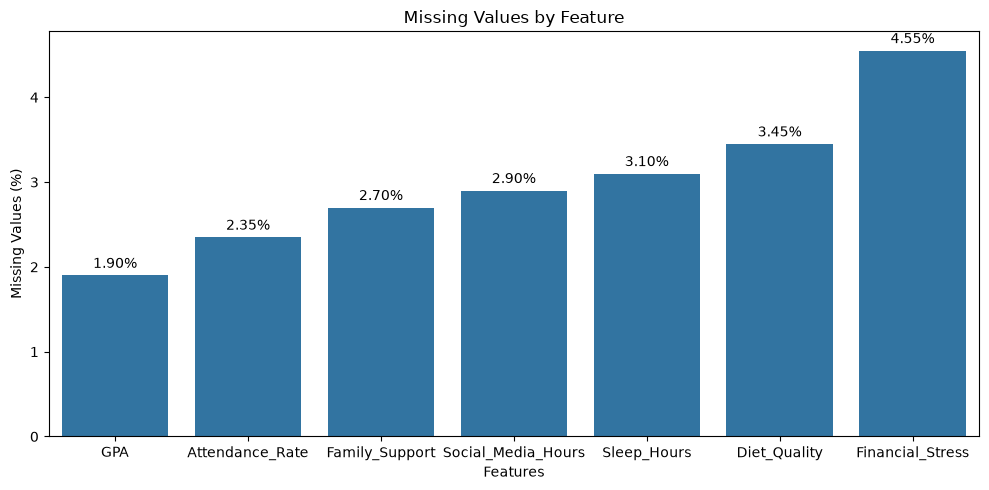

In [14]:
missing = (df.isnull().sum() / len(df) * 100)
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(10, 5))

ax = sns.barplot(x=missing.index, y=missing.values)

print(ax.containers)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Missing Values by Feature")
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")

plt.tight_layout()
save_plot("valuer_manguantes.png")

In [15]:
df.duplicated().sum()

np.int64(0)

### Histogrammes et boxplots

In [16]:
df.select_dtypes(include=np.number).columns

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='object')

In [ ]:
dimention=[1,7]


SyntaxError: invalid syntax (3416374109.py, line 2)

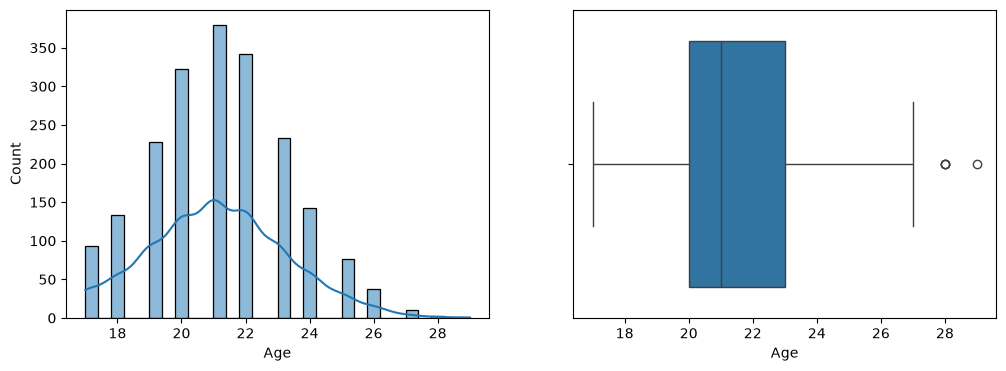

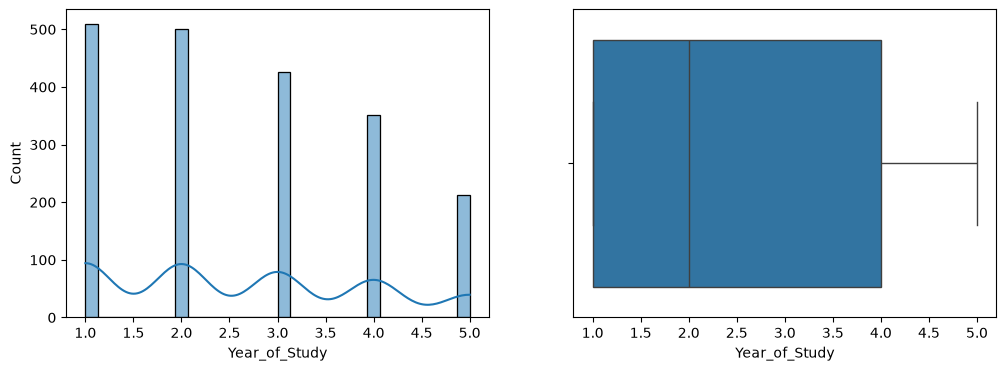

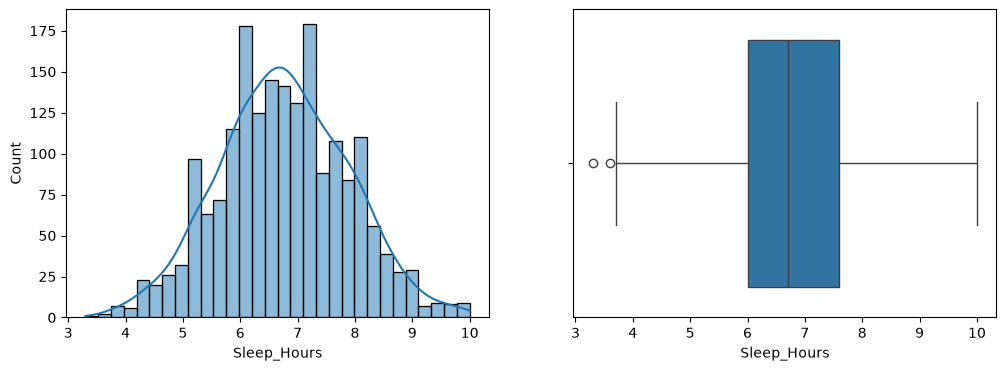

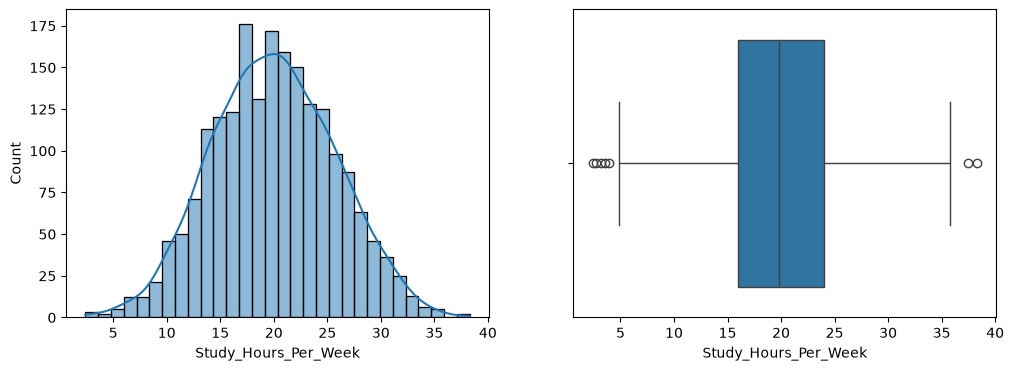

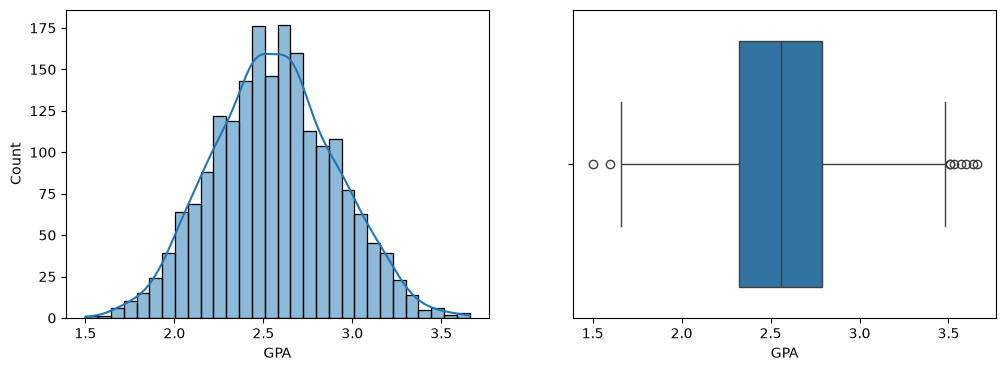

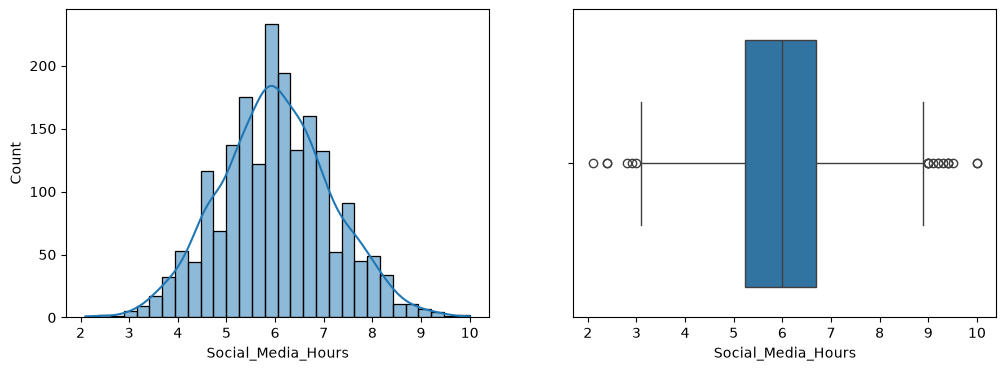

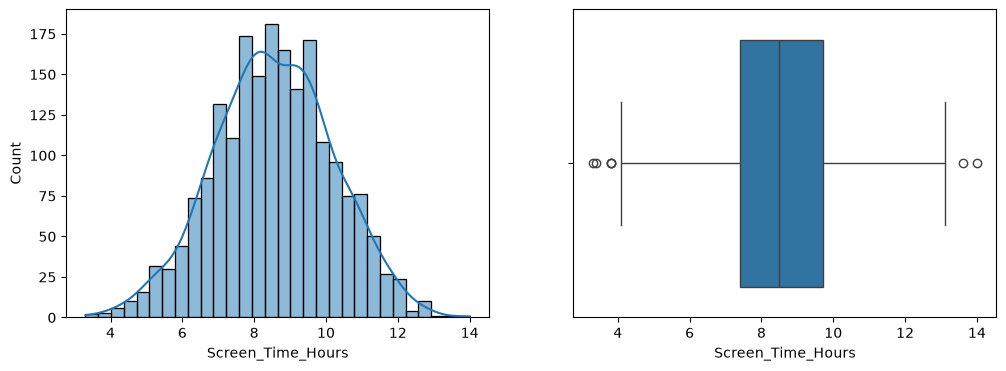

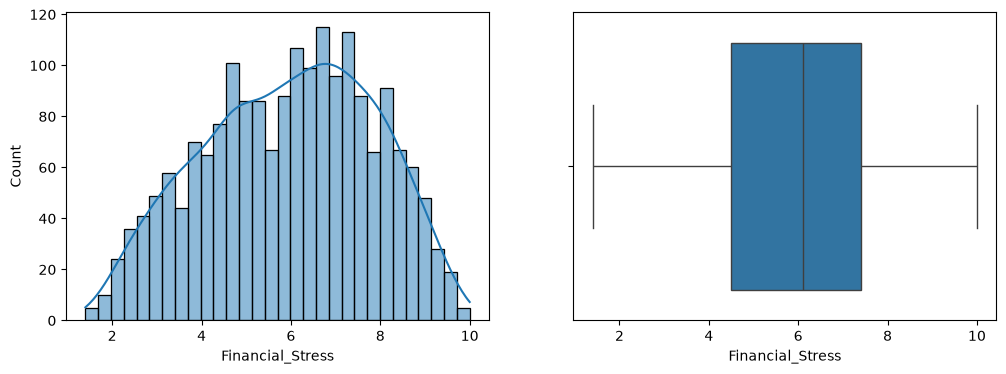

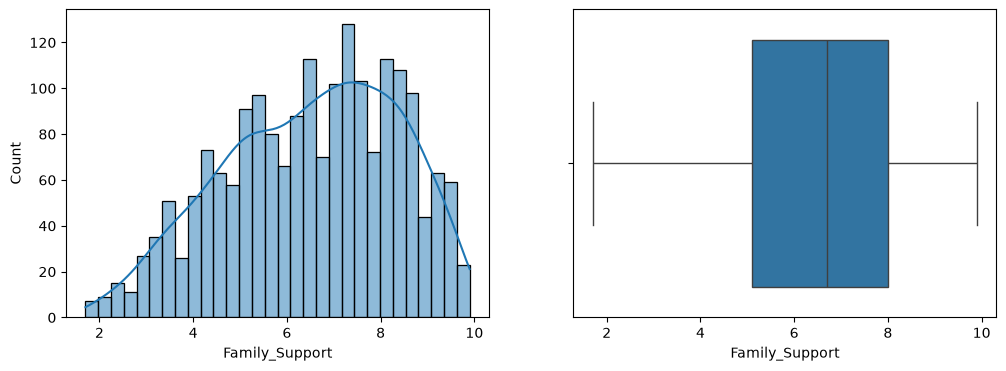

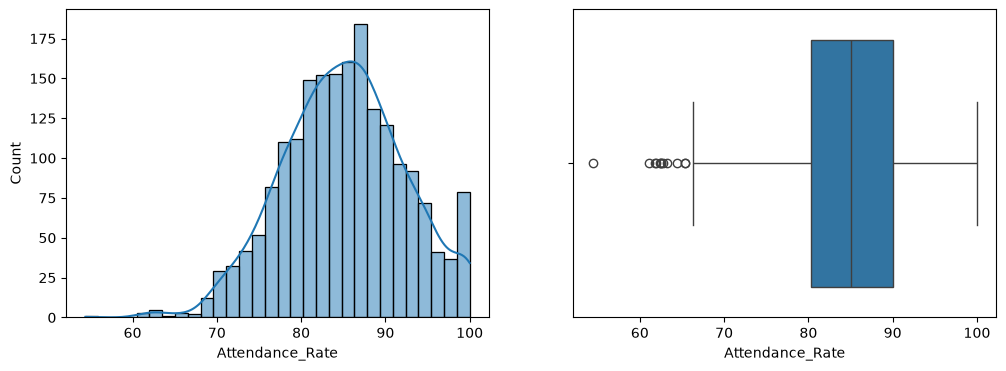

In [38]:
def boxplot_histogram(column):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df,x=column, bins=30, ax=axes[0],kde=True)
    sns.boxplot(x=df[column], ax=axes[1])
    plt.show()
numerical_columns = df.select_dtypes(include=np.number)
for column in numerical_columns:
    boxplot_histogram(column)

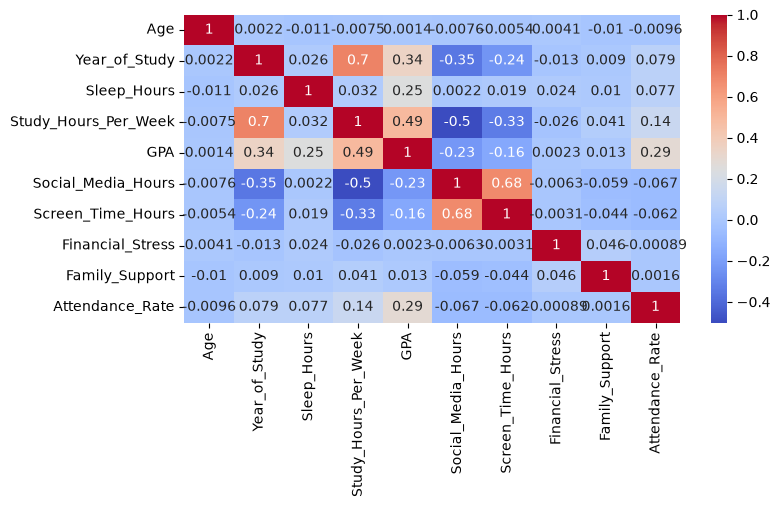

In [18]:
corr = df.select_dtypes(include=np.number).corr()
fig, ax = plt.subplots(figsize=(8,4))
sns.heatmap(corr, annot=True,cmap="coolwarm")
plt.show()

Pearson r: 0.68
Rows compared: 1942


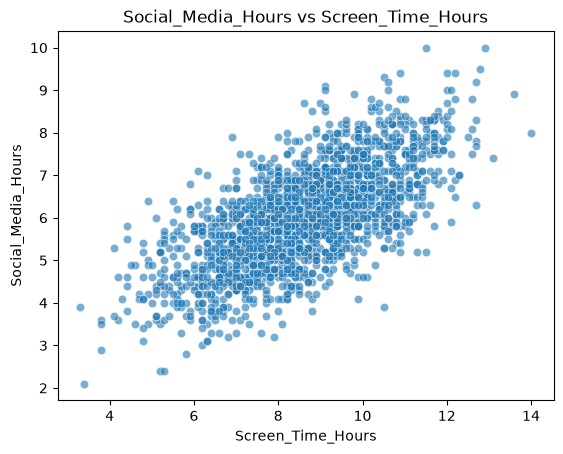

In [19]:
x = "Screen_Time_Hours"
y = "Social_Media_Hours"

pair = df[[x, y]].dropna()

print("Pearson r:", round(pair[x].corr(pair[y]), 2))
print("Rows compared:", len(pair))

# plt.scatter(pair[x], pair[y], alpha=0.3)
sns.scatterplot(df,x=pair[x],y=pair[y],alpha=0.6)
plt.xlabel(x)
plt.ylabel(y)
plt.title(f"{y} vs {x}")
plt.show()

In [20]:
profile = ProfileReport(df, title="EDA_Report")
profile.to_file(ROOT/ "repport" / "eda_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 17/17 [00:00<00:00, 32980.19it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 

In [23]:
age = df["Age"]
year = df["Year_of_Study"]
sleep = df["Sleep_Hours"]
study = df["Study_Hours_Per_Week"]
gpa = df["GPA"]
social = df["Social_Media_Hours"]
screen = df["Screen_Time_Hours"]
stress = df["Financial_Stress"]
support = df["Family_Support"]
attendance = df["Attendance_Rate"]

# Invalid numeric values
Invalid_age_values = age.notna() & ((age < 1) | (age > 120))
Invalid_year_of_study_values = year.notna() & ((year < 1) | (year > 5))
Invalid_Sleep_Hours = (sleep < 0) | (sleep > 24)
Invalid_Study_Hours_Per_Week = (study < 0) | (study > 168)
Invalid_GPA = (gpa < 0) | (gpa > 4)
Invalid_Social_Media_Hours = (social < 0) | (social > 24)
Invalid_Screen_Time_Hours = (screen < 0) | (screen > 24)
Invalid_Financial_Stress = (stress < 1) | (stress > 10)
Invalid_Family_Support = (support < 1) | (support > 10)
Invalid_Attendance_Rate = (attendance < 0) | (attendance > 100)

# Invalid category values
gender = df["Gender"]
activity = df["Physical_Activity"]
job = df["Part_Time_Job"]
diet = df["Diet_Quality"]
history = df["Previous_Mental_Health_History"]

Invalid_Gender = gender.notna() & ~gender.isin(["Female", "Male", "Non-binary"])
Invalid_Physical_Activity = activity.notna() & ~activity.isin(["Low", "Moderate", "High"])
Invalid_Part_Time_Job = job.notna() & ~job.isin(["Yes", "No"])
Invalid_Diet_Quality = diet.notna() & ~diet.isin(["Poor", "Average", "Good"])
Invalid_Previous_Mental_Health_History = history.notna() & ~history.isin(["Yes", "No"])

# Required ID and target
student_id = df["Student_ID"]
Invalid_Student_ID = student_id.isna() | student_id.duplicated(keep=False)
Invalid_Mental_Health_Risk = ~df["Mental_Health_Risk"].isin(["Low", "Medium", "High"])

# Values within the allowed range that are worth reviewing
Suspicious_age_values = ((age < 16) | (age > 70)) & ~Invalid_age_values
Suspicious_Sleep_Hours = ((sleep < 3) | (sleep > 12)) & ~Invalid_Sleep_Hours
Suspicious_Study_Hours_Per_Week = (study > 80) & ~Invalid_Study_Hours_Per_Week
Suspicious_Social_Media_Hours = (social > 12) & ~Invalid_Social_Media_Hours
Suspicious_Screen_Time_Hours = (screen > 18) & ~Invalid_Screen_Time_Hours
Suspicious_Attendance_Rate = (attendance < 60) & ~Invalid_Attendance_Rate

# Compare the two screen-time columns
Suspicious_Screen_Consistency = (
    (social > screen) & ~Invalid_Social_Media_Hours & ~Invalid_Screen_Time_Hours
)

In [24]:
Suspicious_Screen_Consistency.sum()

np.int64(37)

In [58]:
# numerical_columns = df.select_dtypes(include="number").columns.drop(
#     "Mental_Health_Risk", errors="ignore"
# )

# encoder = OrdinalEncoder(categories=[['Low', 'Medium','High']])
# df["Mental_Health_Risk_Encoder"]= encoder.fit_transform(df[["Mental_Health_Risk"]])
# correlations = (
#     df[numerical_columns]
#     .corrwith(df["Mental_Health_Risk_Encoder"])
#     .sort_values(key=abs, ascending=False)
# )

# print(correlations)

In [ ]:
# df = df[~Suspicious_Screen_Consistency]